# Reproducible Clifford/T check study

Run from the repository root with the locked Python environment plus requirements-draw.txt. All circuits execute locally. The synthetic noise and separate Paulice metric are documented in docs/SCIENTIFIC_REPORT.md. “Best” is restricted to the stated family. No claimed hardware calibration.


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / "backend").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from scripts.run_track_experiments import experiment
# Preserve the matched-study protocol and its original F_ps/S_keep data.
# Regenerate this artifact with scripts/run_track_experiments.py, without
# substituting mission noise or assigning a mission budget to this study.
results = json.loads((ROOT / "docs/TRACK_EXPERIMENTS.json").read_text(encoding="utf-8"))
print(results["noise"])
print(results["scope"])
print(results["packages"])


Uniform synthetic depolarizing lambda=.01 after each serialized gate on every live wire; identities retain doping slots. Separate Paulice observable benchmarks use gate_noise=.01, readout_noise=.015 and the documented legacy gate-local Aer noise; do not numerically merge those estimators with coherent state-fidelity rows. No readout error, hardware execution or calibration claim.
Matched 3-data-qubit backbone, repetitions 1/3 and four identity-or-T doping slots. Separate Paulice Clifford benchmarks: budgets 1/2 and orders [0,1]/[1,0]. T search enumerates seven full-span Z/I openings with one helper; best found, not an unrestricted optimum.
{'qiskit': '2.5.2', 'qiskit-aer': '0.17.2', 'qiskit-paulice': '0.2.1', 'numpy': '2.2.6'}


In [2]:
rows = results["rows"]
print("repetitions T depth method F_unchecked F_ps S_keep correct_shot_yield Trusted_Fidelity(no_budget=N/A) +anc +2q +depth")
for row in rows:
    print(row["repetitions"], row["tCount"], row["payloadDepth"], row["method"], *[round(row[k], 5) for k in ("uncheckedFidelity", "fidelity", "retention", "correct_shot_yield")], "N/A", *[row[k] for k in ("addedAncillas", "addedTwoQubit", "addedDepth")])


repetitions T depth method F_unchecked F_ps S_keep correct_shot_yield Trusted_Fidelity(no_budget=N/A) +anc +2q +depth
1 0 4 unchecked 0.85409 0.85409 1.0 0.85409 N/A 0 0 0
1 0 4 custom-Z-search 0.85409 0.8531 0.83449 0.7119 N/A 1 4 6
1 0 4 custom-Z-search 0.85409 0.83889 0.86985 0.72971 N/A 1 3 5
1 0 4 custom-Z-search 0.85409 0.83767 0.87736 0.73494 N/A 1 3 5
1 0 4 custom-Z-search 0.85409 0.83858 0.86985 0.72944 N/A 1 3 4
1 0 4 custom-Z-search 0.85409 0.85978 0.81176 0.69794 N/A 1 5 6
1 0 4 custom-Z-search 0.85409 0.84695 0.84472 0.71544 N/A 1 4 5
1 0 4 custom-Z-search 0.85409 0.85647 0.79948 0.68473 N/A 1 6 7
1 1 4 unchecked 0.85409 0.85409 1.0 0.85409 N/A 0 0 0
1 1 4 custom-Z-search 0.85409 0.83889 0.86985 0.72971 N/A 1 3 5
1 1 4 custom-Z-search 0.85409 0.83858 0.86985 0.72944 N/A 1 3 4
1 1 4 custom-Z-search 0.85409 0.84695 0.84472 0.71544 N/A 1 4 5
1 2 4 unchecked 0.85409 0.85409 1.0 0.85409 N/A 0 0 0
1 2 4 custom-Z-search 0.85409 0.83858 0.86985 0.72944 N/A 1 3 4
1 4 4 unchecked 0.

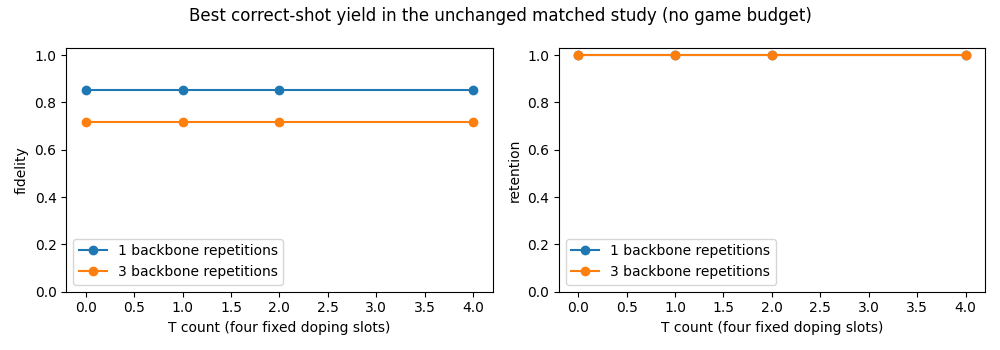

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for repetitions in (1, 3):
    selected = [max((r for r in rows if r["repetitions"] == repetitions and r["tCount"] == t), key=lambda r: r["correct_shot_yield"]) for t in (0, 1, 2, 4)]
    for ax, metric in zip(axes, ("fidelity", "retention")):
        ax.plot([r["tCount"] for r in selected], [r[metric] for r in selected], "o-", label=f"{repetitions} backbone repetitions")
        ax.set(xlabel="T count (four fixed doping slots)", ylabel=metric, ylim=(0, 1.03))
        ax.legend()
fig.suptitle("Best correct-shot yield in the unchanged matched study (no game budget)")
fig.tight_layout()
plt.show()


In [4]:
print("Separate observable estimator: do not merge with the state-fidelity plot")
for r in results["pauliceObservableBenchmarks"]:
    print(r["repetitions"], r["targets"], "F estimate", round(r["fidelity"], 5), "kept", round(r["retention"], 5), "added checks", r["checks"], "added 2q", r["addedTwoQubit"], "depth", r["depth"])
assert any(r["checks"] > 0 for r in results["pauliceObservableBenchmarks"])
assert all(0 <= r["retention"] <= 1 for r in rows)
print("Verified actual Paulice insertions and physical retained fractions.")


Separate observable estimator: do not merge with the state-fidelity plot
1 [0] F estimate 0.92407 kept 1.0 added checks 0 added 2q 0 depth 6
1 [1] F estimate 0.94339 kept 0.94155 added checks 1 added 2q 3 depth 16
1 [0, 1] F estimate 0.94339 kept 0.94155 added checks 1 added 2q 3 depth 16
1 [1, 0] F estimate 0.94339 kept 0.94155 added checks 1 added 2q 3 depth 16
3 [0] F estimate 0.93703 kept 0.92229 added checks 1 added 2q 3 depth 19
3 [1] F estimate 0.95006 kept 0.91406 added checks 1 added 2q 3 depth 21
3 [0, 1] F estimate 0.97544 kept 0.85854 added checks 2 added 2q 6 depth 24
3 [1, 0] F estimate 0.9594 kept 0.85658 added checks 2 added 2q 7 depth 23
Verified actual Paulice insertions and physical retained fractions.


## Interpretation

Trusted Fidelity is a game objective with an explicit per-level shot budget, not the unbudgeted objective of this matched study. No game budget is assigned here; its Trusted Fidelity entry is N/A. The original F_ps and S_keep data and noise protocol are preserved. Conditional fidelity alone is insufficient. Read it together with retained yield and interaction/depth costs. Uniform noise may favor unchecked execution; the game deliberately adds a disclosed localized relaxation hotspot. T gates restrict Pauli admissibility. Paulice is used only for its Clifford observable benchmark; the T search is custom. See the written report for limitations and the level validation table for gameplay targets.
